## Variatinal Autoencoder (VAEs):

Variational Autoencoders (VAEs) are generative models that learn a smooth, probabilistic latent space, allowing them not only to compress and reconstruct data but also to generate entirely new, realistic samples. VAEs capture the underlying structure of a dataset and produce outputs that closely resemble the original data.

- Learns a continuous latent representation
- Enables controlled and meaningful data generation
- Widely used in image synthesis, anomaly detection, and representation learning


## Variatinal Autoencoder (VAEs) Architecture:
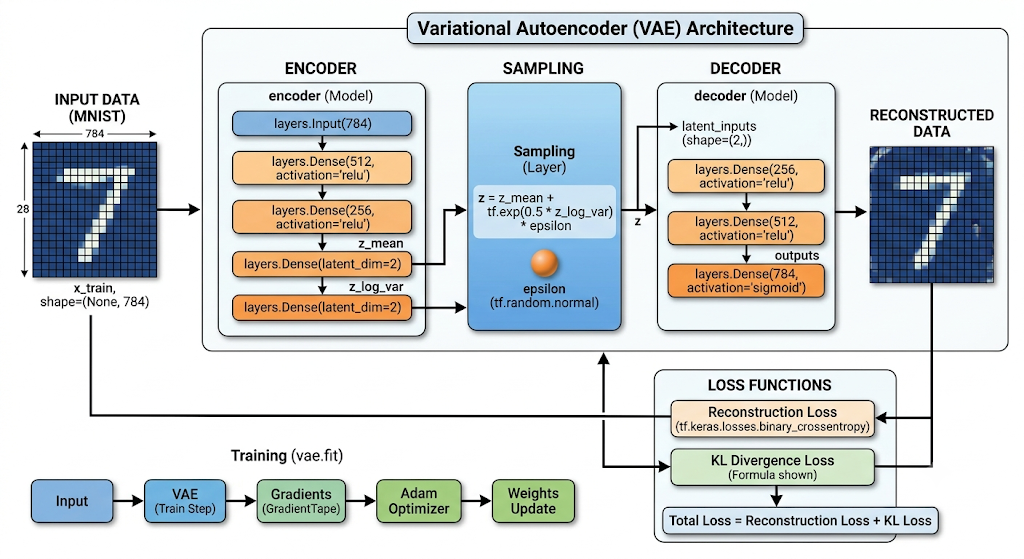

## Using Karas Libray Import

In [44]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Model
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
# ===========================
# Load MNIST
# ===========================
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.
x_test = x_test.astype("float32") / 255.
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

latent_dim = 2

In [46]:
# ===========================
# Encoder
# ===========================
inputs = layers.Input(shape=(784,))
x = layers.Dense(512, activation="relu")(inputs)
x = layers.Dense(256, activation="relu")(x)
z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

In [47]:
# ===========================
# Sampling Layer
# ===========================
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

    def compute_output_shape(self, input_shape):
        return input_shape[0]


z = Sampling()([z_mean, z_log_var])
encoder = Model(
    inputs,
    [z_mean, z_log_var, z],
    name="encoder"
)

In [48]:
# ===========================
# Decoder
# ===========================

latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(256, activation="relu")(latent_inputs)
x = layers.Dense(512, activation="relu")(x)
outputs = layers.Dense(784,activation="sigmoid")(x)

decoder = Model(
    latent_inputs,
    outputs,
    name="decoder"
)

In [49]:
# ===========================
# VAE
# ===========================
class VAE(Model):
    def __init__(
        self,
        encoder,
        decoder,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(
                    data,
                    reconstruction
                )
            ) * 784

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = (
                reconstruction_loss +
                kl_loss
            )

        grads = tape.gradient(
            total_loss,
            self.trainable_weights
        )
        self.optimizer.apply_gradients(
            zip(
                grads,
                self.trainable_weights
            )
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }


### VAE Model Define

In [50]:
vae_model = VAE(
    encoder,
    decoder
)

# Comple Model with Adam Optimizer
vae_model.compile(
    optimizer="adam"
)

# Fit Train Data in Model and Train
history = vae_model.fit(x_train, epochs=20, batch_size=128)


Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - kl_loss: 4.6190 - loss: 164.5093 - reconstruction_loss: 159.8903
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 5.3585 - loss: 164.2818 - reconstruction_loss: 158.9234
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - kl_loss: 5.7083 - loss: 159.3315 - reconstruction_loss: 153.6233
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 5.9781 - loss: 149.3224 - reconstruction_loss: 143.3443
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 6.0152 - loss: 153.2177 - reconstruction_loss: 147.2025
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 5.9258 - loss: 143.6253 - reconstruction_loss: 137.6995
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 5.9065 - loss: 148.0287 - reconstruction_loss: 142.1222
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 6.2799 - loss: 139.3454 - reconstruction_loss: 133.0655
Epoch 9/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


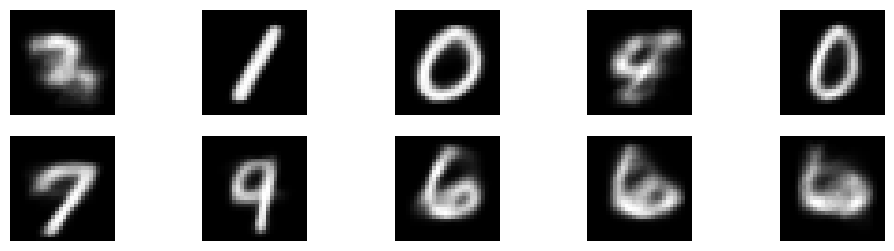

In [51]:
# Randome Decoded Ramdom Sample data 
z_sample = np.random.normal(
    size=(10, latent_dim)
)
generated = decoder.predict(
    z_sample
)
plt.figure(figsize=(12,3))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(
        generated[i].reshape(28,28),
        cmap="gray"
    )
    plt.axis("off")
    
plt.show()

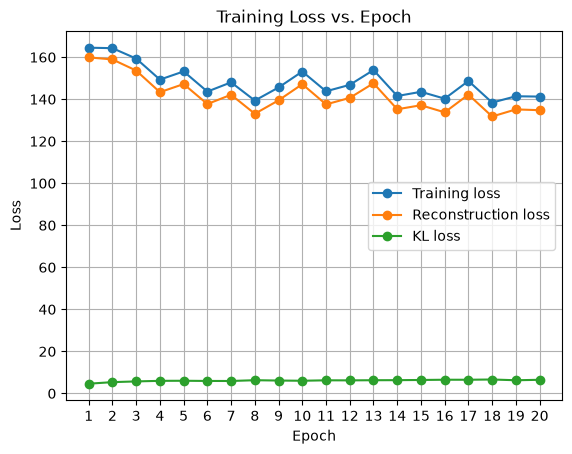

In [52]:
# Training Epoch vs Loss Graph
import matplotlib.pyplot as plt
epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs, history.history["reconstruction_loss"], marker="o", label="Reconstruction loss")
plt.plot(epochs, history.history["kl_loss"], marker="o", label="KL loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs. Epoch")
plt.xticks(epochs)
plt.grid(True)
plt.legend()
plt.show()

In [53]:
def plot_vae_matrix(df):
    plt.figure(figsize=(9, 6))
    sns.heatmap(df, annot=True, cmap="Spectral_r", fmt=".2f", linewidths=.5, cbar=True)
    plt.title("VAE Model Evolution Matrix (Losses across Epochs)", fontsize=14, pad=15)
    plt.xlabel("VAE Metrics", fontsize=12)
    plt.ylabel("Training Epochs", fontsize=12)
    plt.tight_layout()
    plt.savefig("vae_model_evolution_matrix.png", dpi=300)
    plt.show()

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 6.4631 - loss: 147.9879 - reconstruction_loss: 141.5247
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 6.4121 - loss: 135.1724 - reconstruction_loss: 128.7603
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 6.4372 - loss: 141.5510 - reconstruction_loss: 135.1138
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 6.5876 - loss: 138.8673 - reconstruction_loss: 132.2797
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 6.6623 - loss: 139.9183 - reconstruction_loss: 133.2560
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 6.6020 - loss: 137.5588 - reconstruction_loss: 130.9567
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 6.8647 - loss: 138.1224 - reconstruction_loss: 131.2576
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 6.7916 - loss: 145.5760 - reconstruction_loss: 138.7843
Epoch 9/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/s

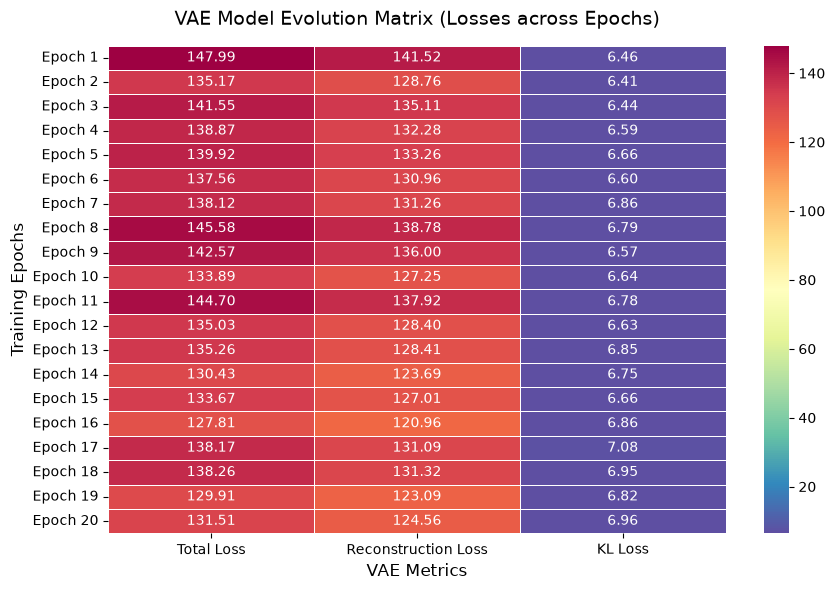

In [54]:
from tensorflow.keras.callbacks import Callback
class VAEEvolutionLogger(Callback):
    def __init__(self):
        self.history_matrix = []
    def on_epoch_end(self, epoch, logs=None):
        self.history_matrix.append({
            "Epoch": f"Epoch {epoch + 1}",
            "Total Loss": logs.get("loss"),
            "Reconstruction Loss": logs.get("reconstruction_loss"),
            "KL Loss": logs.get("kl_loss")
        })

# Usage during training:
logger = VAEEvolutionLogger()
vae_model.fit(x_train, epochs=20, batch_size=128, callbacks=[logger])

# Convert logged history to DataFrame matrix:
df_matrix = pd.DataFrame(logger.history_matrix).set_index("Epoch")
plot_vae_matrix(df_matrix)